# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset **tanpa label** dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.
   
2. **Ketentuan Dataset**:
   - **Tanpa label**: Dataset tidak boleh memiliki label atau kelas.
   - **Jumlah Baris**: Minimal 1000 baris untuk memastikan dataset cukup besar untuk analisis yang bermakna.
   - **Tipe Data**: Harus mengandung data **kategorikal** dan **numerikal**.
     - *Kategorikal*: Misalnya jenis kelamin, kategori produk.
     - *Numerikal*: Misalnya usia, pendapatan, harga.

3. **Pembatasan**:  
   Dataset yang sudah digunakan dalam latihan clustering (seperti customer segmentation) tidak boleh digunakan.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [80]:
import pandas as pd  # Untuk membaca dan mengolah data
import numpy as np  # Untuk operasi numerik
import matplotlib.pyplot as plt  # Untuk visualisasi data
import seaborn as sns  # Untuk visualisasi data
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans  # Algoritma clustering
from sklearn.metrics import silhouette_score  # Evaluasi jumlah cluster
from IPython.display import display, Markdown
from yellowbrick.cluster import KElbowVisualizer
from sklearn.decomposition import PCA

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

In [81]:
# Memuat dataset
file_path = "Dataset_clustering.csv"
df = pd.read_csv(file_path)  # Membaca dataset CSV ke dalam DataFrame

# Menampilkan ringkasan informasi dataset
print(df.info())

# Menampilkan ringkasan statistik untuk semua kolom
print(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4620 entries, 0 to 4619
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   provinsi  4620 non-null   object 
 1   daerah    4620 non-null   object 
 2   jenis     4620 non-null   object 
 3   tahun     4620 non-null   int64  
 4   peng      4512 non-null   float64
dtypes: float64(1), int64(1), object(3)
memory usage: 180.6+ KB
None
       provinsi     daerah    jenis        tahun          peng
count      4620       4620     4620  4620.000000  4.512000e+03
unique       35          3        3          NaN           NaN
top        ACEH  PERDESAAN  MAKANAN          NaN           NaN
freq        132       1680     1540          NaN           NaN
mean        NaN        NaN      NaN  2015.045455  6.012012e+05
std         NaN        NaN      NaN     4.416124  3.524052e+05
min         NaN        NaN      NaN  2007.000000  5.921600e+04
25%         NaN        NaN      NaN  2011.750000

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset. EDA bertujuan untuk:

1. **Memahami Struktur Data**
   - Tinjau jumlah baris dan kolom dalam dataset.  
   - Tinjau jenis data di setiap kolom (numerikal atau kategorikal).

2. **Menangani Data yang Hilang**  
   - Identifikasi dan analisis data yang hilang (*missing values*). Tentukan langkah-langkah yang diperlukan untuk menangani data yang hilang, seperti pengisian atau penghapusan data tersebut.

3. **Analisis Distribusi dan Korelasi**  
   - Analisis distribusi variabel numerik dengan statistik deskriptif dan visualisasi seperti histogram atau boxplot.  
   - Periksa hubungan antara variabel menggunakan matriks korelasi atau scatter plot.

4. **Visualisasi Data**  
   - Buat visualisasi dasar seperti grafik distribusi dan diagram batang untuk variabel kategorikal.  
   - Gunakan heatmap atau pairplot untuk menganalisis korelasi antar variabel.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

**1. Analisa Struktur Data**

Jumlah baris dan kolom dalam dataset: (4620, 5)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4620 entries, 0 to 4619
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   provinsi  4620 non-null   object 
 1   daerah    4620 non-null   object 
 2   jenis     4620 non-null   object 
 3   tahun     4620 non-null   int64  
 4   peng      4512 non-null   float64
dtypes: float64(1), int64(1), object(3)
memory usage: 180.6+ KB

5 baris pertama dataset:
  provinsi     daerah    jenis  tahun      peng
0     ACEH  PERDESAAN  MAKANAN   2007  195176.0
1     ACEH  PERDESAAN  MAKANAN   2008  218781.0
2     ACEH  PERDESAAN  MAKANAN   2009  247427.0
3     ACEH  PERDESAAN  MAKANAN   2010  275749.0
4     ACEH  PERDESAAN  MAKANAN   2011  308000.0


**2. Menangani Data yang Hilang**


Jumlah data yang hilang per kolom:
provinsi      0
daerah        0
jenis         0
tahun         0
peng        108
dtype: int64


**3. Analisis Distribusi dan Korelasi**


Statistik deskriptif untuk variabel numerik:
             tahun          peng
count  4620.000000  4.620000e+03
mean   2015.045455  6.012012e+05
std       4.416124  3.482609e+05
min    2007.000000  5.921600e+04
25%    2011.750000  3.528985e+05
50%    2015.000000  5.307305e+05
75%    2019.000000  7.527372e+05
max    2022.000000  2.525347e+06


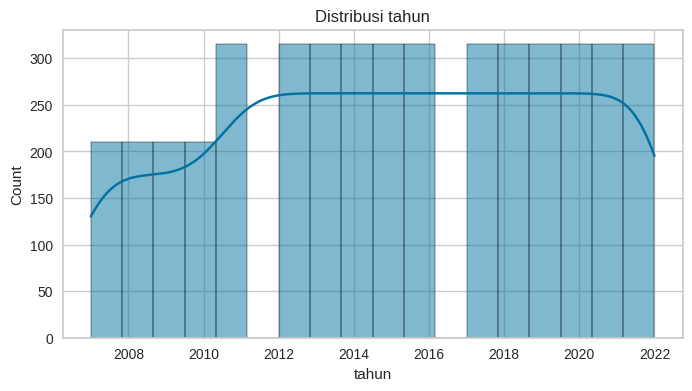

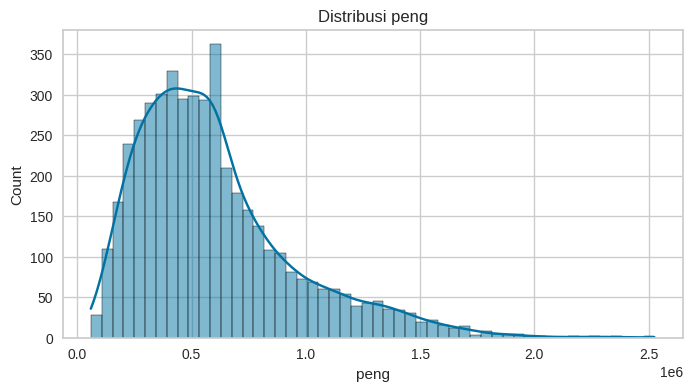

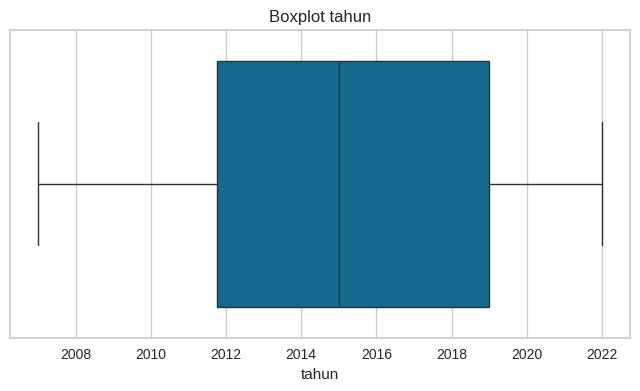

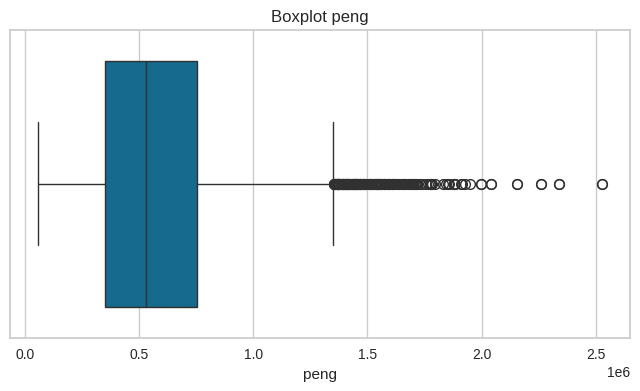

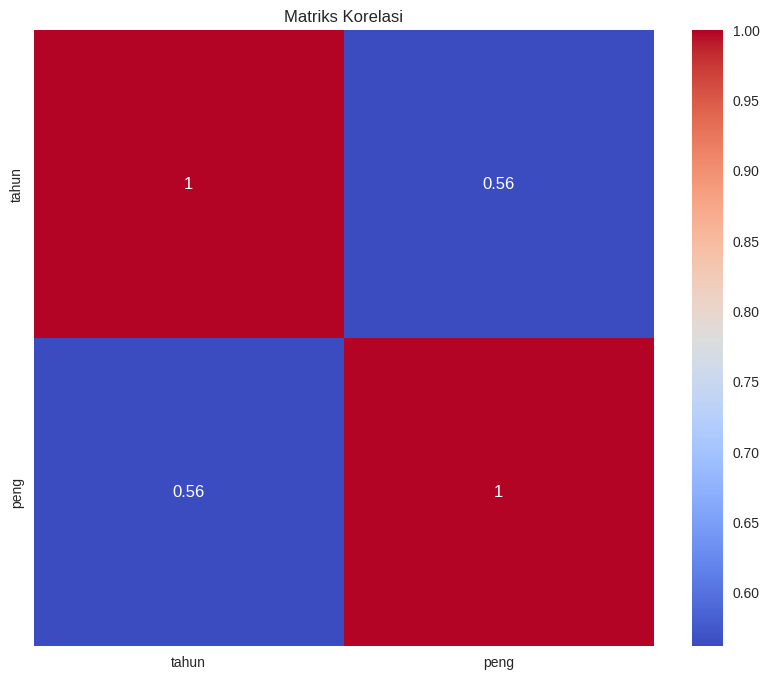

**4. Visualisasi Data**

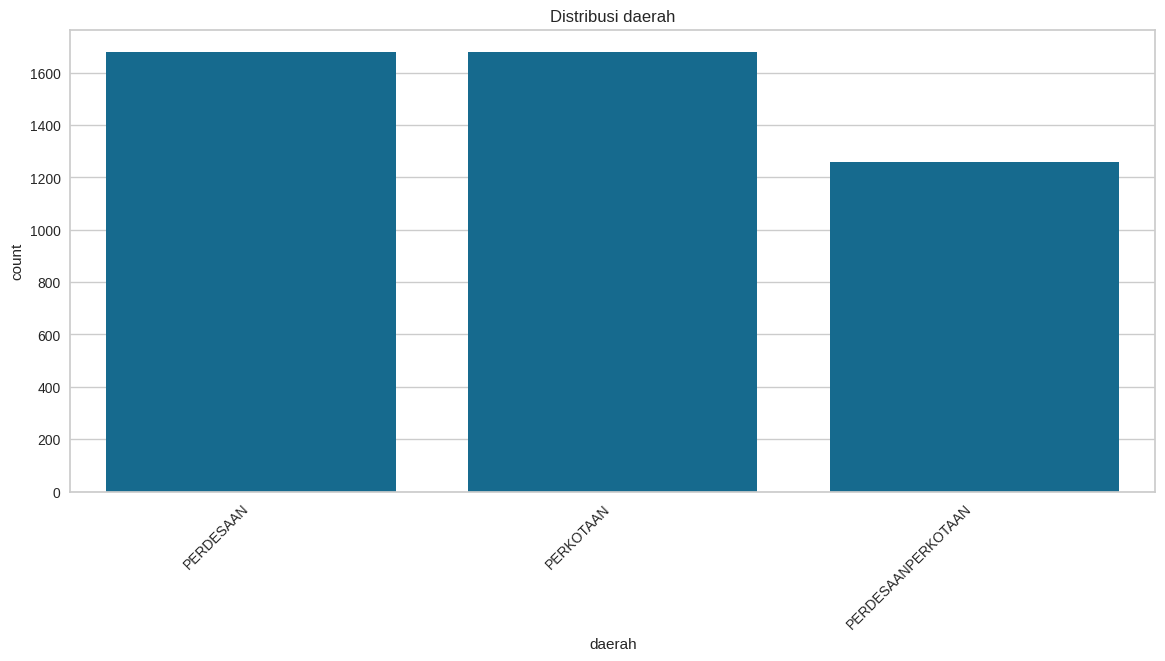

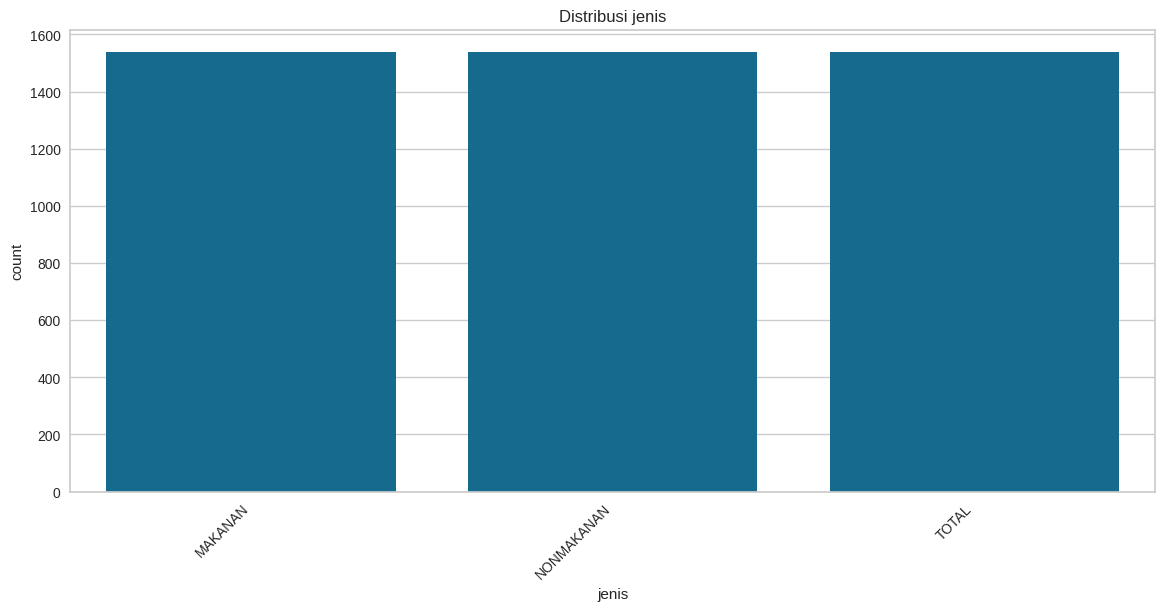

**Korelasi Antar Variabel**

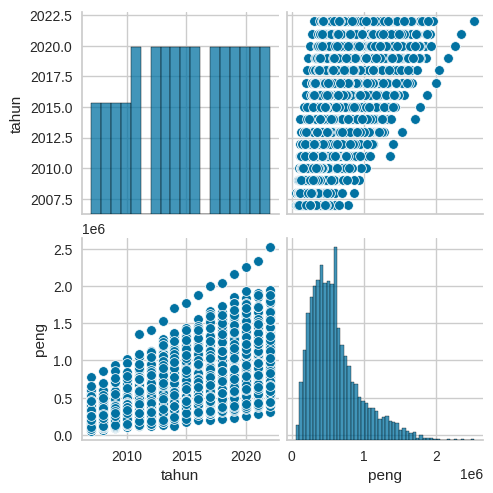

In [82]:
# 1. Memahami Struktur Data
display(Markdown("**1. Analisa Struktur Data**"))
print("Jumlah baris dan kolom dalam dataset:", df.shape)
print("\nInformasi dataset:")
df.info()
print("\n5 baris pertama dataset:")
print(df.head())

# 2. Menangani Data yang Hilang
display(Markdown("**2. Menangani Data yang Hilang**"))
print("\nJumlah data yang hilang per kolom:")
print(df.isnull().sum())

# Mengisi data yang hilang hanya untuk kolom numerik
numerical_columns = df.select_dtypes(include=[np.number]).columns
df[numerical_columns] = df[numerical_columns].fillna(df[numerical_columns].mean()).copy()

# 3. Analisis Distribusi dan Korelasi
display(Markdown("**3. Analisis Distribusi dan Korelasi**"))
# Statistik deskriptif untuk variabel numerik
print("\nStatistik deskriptif untuk variabel numerik:")
print(df[numerical_columns].describe())

# Visualisasi distribusi variabel numerik
for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribusi {col}')
    plt.show()

# Boxplot untuk variabel numerik
for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot {col}')
    plt.show()

# Matriks korelasi
correlation_matrix = df[numerical_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriks Korelasi')
plt.show()

# 4. Visualisasi Data
display(Markdown("**4. Visualisasi Data**"))
# Visualisasi distribusi variabel kategorikal
categorical_columns = df.select_dtypes(include=['object']).columns
for col in categorical_columns:
    if df[col].nunique() < 20:  # Hanya tampilkan jika kategori < 20
        plt.figure(figsize=(14, 6))
        sns.countplot(x=df[col], order=df[col].value_counts().index)
        plt.title(f'Distribusi {col}')
        plt.xticks(rotation=45, ha='right')
        plt.show()

# Pairplot untuk menganalisis korelasi antar variabel numerik
display(Markdown("**Korelasi Antar Variabel**"))
sns.pairplot(df[numerical_columns])
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah.

Jumlah data yang hilang per kolom sebelum penanganan:
provinsi    0
daerah      0
jenis       0
tahun       0
peng        0
dtype: int64

Jumlah data yang hilang per kolom setelah penanganan:
provinsi    0
daerah      0
jenis       0
tahun       0
peng        0
dtype: int64

Jumlah data duplikat sebelum penghapusan: 0
Jumlah data duplikat setelah penghapusan: 0


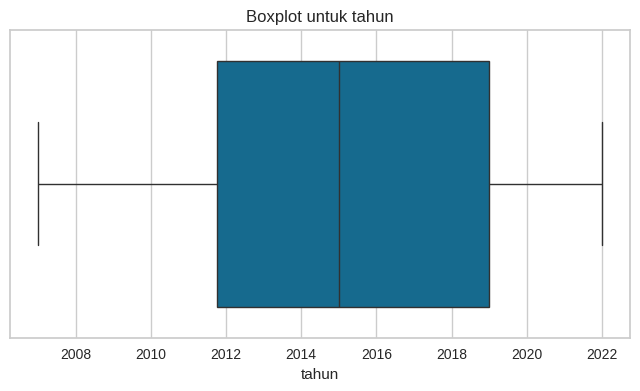

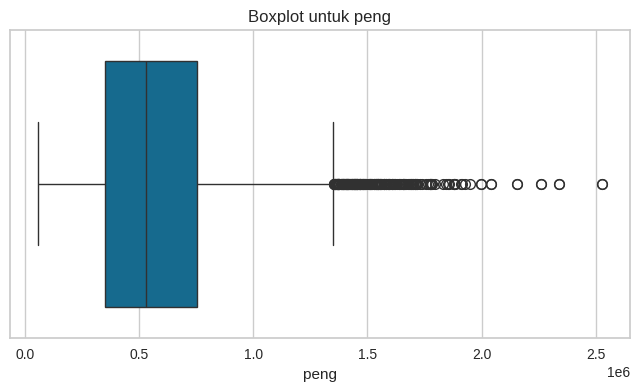


Data setelah penanganan outlier:
  provinsi     daerah    jenis   tahun      peng
0     ACEH  PERDESAAN  MAKANAN  2007.0  195176.0
1     ACEH  PERDESAAN  MAKANAN  2008.0  218781.0
2     ACEH  PERDESAAN  MAKANAN  2009.0  247427.0
3     ACEH  PERDESAAN  MAKANAN  2010.0  275749.0
4     ACEH  PERDESAAN  MAKANAN  2011.0  308000.0

Data setelah binning:
       peng peng_binned
0  195176.0      rendah
1  218781.0      rendah
2  247427.0      rendah
3  275749.0      rendah
4  308000.0      rendah

Data setelah encoding kategorikal:
    tahun      peng peng_binned  provinsi_BALI  provinsi_BANTEN  \
0  2007.0  195176.0      rendah          False            False   
1  2008.0  218781.0      rendah          False            False   
2  2009.0  247427.0      rendah          False            False   
3  2010.0  275749.0      rendah          False            False   
4  2011.0  308000.0      rendah          False            False   

   provinsi_BENGKULU  provinsi_DI YOGYAKARTA  provinsi_DKI JAKARTA

In [83]:
# 1. Menghapus atau Menangani Data Kosong (Missing Values)
print("Jumlah data yang hilang per kolom sebelum penanganan:")
print(df.isnull().sum())

# Mengisi data kosong untuk kolom numerik dengan rata-rata
numerical_columns = df.select_dtypes(include=[np.number]).columns
df[numerical_columns] = df[numerical_columns].fillna(df[numerical_columns].mean())

# Mengisi data kosong untuk kolom kategorikal dengan nilai mode
categorical_columns = df.select_dtypes(include=['object']).columns
for col in categorical_columns:
    if df[col].isnull().all():  # Jika semua data di kolom ini NaN
        df[col] = df[col].fillna('Unknown')
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nJumlah data yang hilang per kolom setelah penanganan:")
print(df.isnull().sum())

# 2. Menghapus Data Duplikat
print("\nJumlah data duplikat sebelum penghapusan:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Jumlah data duplikat setelah penghapusan:", df.duplicated().sum())

# 3. Deteksi dan Penanganan Outlier
# Deteksi outlier dengan boxplot
for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot untuk {col}')
    plt.show()

# Penanganan outlier menggunakan metode IQR (Interquartile Range)
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("\nData setelah penanganan outlier:")
print(df.head())

# 4. Binning (Pengelompokan Data)
if 'peng' in df.columns:
    df['peng_binned'] = pd.cut(df['peng'], bins=3, labels=['rendah', 'sedang', 'tinggi'])
    print("\nData setelah binning:")
    print(df[['peng', 'peng_binned']].head())

# 5. Encoding Data Kategorikal
df = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

print("\nData setelah encoding kategorikal:")
print(df.head())

# 6. Normalisasi atau Standarisasi Fitur
# Normalisasi menggunakan MinMaxScaler (mengubah nilai ke rentang 0-1)
min_max_scaler = MinMaxScaler()
df[numerical_columns] = min_max_scaler.fit_transform(df[numerical_columns])

print("\nData setelah normalisasi:")
print(df.head())


# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan. Berikut adalah **rekomendasi** tahapannya.
1. Pilih algoritma clustering yang sesuai.
2. Latih model dengan data menggunakan algoritma tersebut.

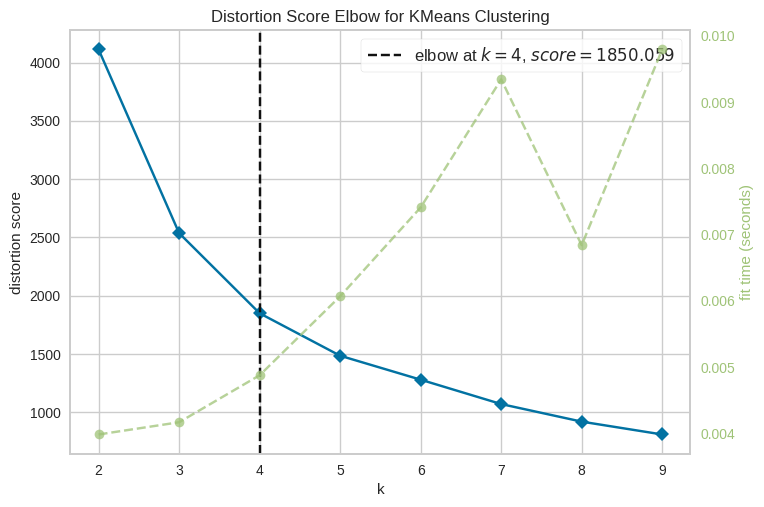

      tahun      peng peng_binned  provinsi_BALI  provinsi_BANTEN  \
0  0.000000  0.105128      rendah          False            False   
1  0.066667  0.123380      rendah          False            False   
2  0.133333  0.145530      rendah          False            False   
3  0.200000  0.167429      rendah          False            False   
4  0.266667  0.192367      rendah          False            False   

   provinsi_BENGKULU  provinsi_DI YOGYAKARTA  provinsi_DKI JAKARTA  \
0              False                   False                 False   
1              False                   False                 False   
2              False                   False                 False   
3              False                   False                 False   
4              False                   False                 False   

   provinsi_GORONTALO  provinsi_INDONESIA  ...  provinsi_SULAWESI TENGGARA  \
0               False               False  ...                       False   
1       

In [84]:
# Memilih kolom yang relevan untuk clustering
# Misalnya, kita akan menggunakan kolom 'peng' sebagai fitur
X = df[['tahun', 'peng']]

# Normalisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menentukan jumlah cluster (k) -> nilai awal, nanti akan divalidasi di evaluasi
k = 3  # Contoh, kita pilih 3 cluster

# Mencari jumlah cluster optimal dengan Elbow Method
elbow_visualizer = KElbowVisualizer(KMeans(random_state=42), k=(2,10))
elbow_visualizer.fit(X_scaled)
elbow_visualizer.show()

# Membuat model K-Means
kmeans = KMeans(n_clusters=k, random_state=42)

# Melatih model
kmeans.fit(X_scaled)

# Menambahkan label cluster ke dataset
df['cluster'] = kmeans.labels_

# Menampilkan beberapa baris pertama dari dataset dengan label cluster
print(df.head())


## **b. Evaluasi Model Clustering**

Untuk menentukan jumlah cluster yang optimal dalam model clustering, Anda dapat menggunakan metode Elbow atau Silhouette Score.

Metode ini membantu kita menemukan jumlah cluster yang memberikan pemisahan terbaik antar kelompok data, sehingga model yang dibangun dapat lebih efektif. Berikut adalah **rekomendasi** tahapannya.
1. Gunakan Silhouette Score dan Elbow Method untuk menentukan jumlah cluster optimal.
2. Hitung Silhouette Score sebagai ukuran kualitas cluster.

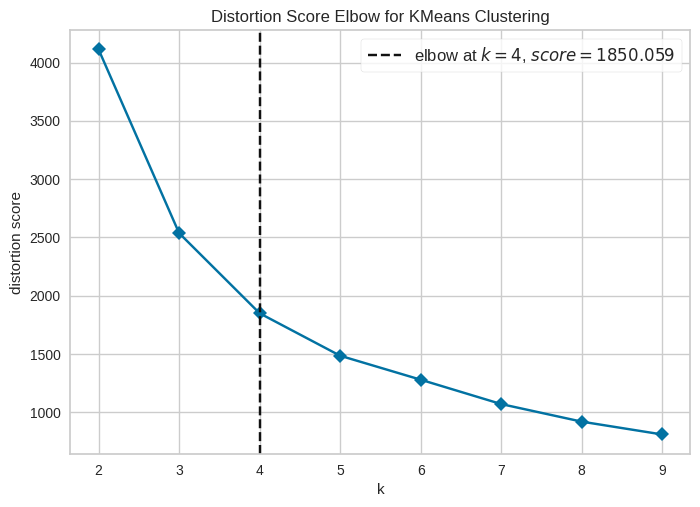

Silhouette Score untuk k=2: 0.467
Silhouette Score untuk k=3: 0.451
Silhouette Score untuk k=4: 0.404
Silhouette Score untuk k=5: 0.412
Silhouette Score untuk k=6: 0.374
Silhouette Score untuk k=7: 0.385
Silhouette Score untuk k=8: 0.385
Silhouette Score untuk k=9: 0.385


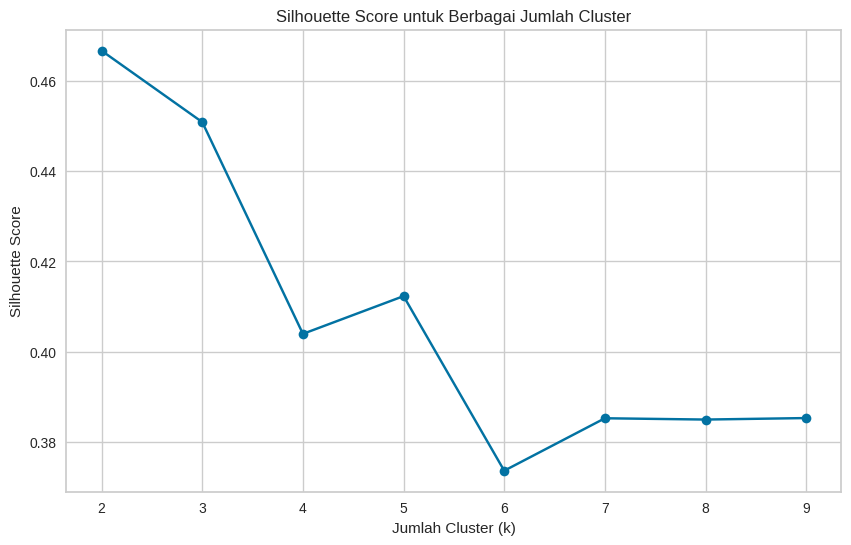


Rekomendasi Jumlah Cluster:
- Berdasarkan Elbow Method: 4 cluster
- Berdasarkan Silhouette Score: 2 cluster


In [85]:
# 1. EVALUASI DENGAN ELBOW METHOD (MENGGUNAKAN YELLOWBRICK)
# Inisialisasi model KMeans dengan random_state untuk reproducibility
kmeans_elbow = KMeans(random_state=42)

# Membuat visualizer untuk Elbow Method
visualizer = KElbowVisualizer(
    kmeans_elbow,
    k=(2, 10),  # Mengeksplorasi jumlah cluster dari 2 hingga 10
    metric='distortion',  # Metrik yang digunakan (inertia)
    timings=False  # Menonaktifkan waktu eksekusi
)

# Melatih visualizer dengan data yang telah dinormalisasi
visualizer.fit(X_scaled)

# Mendapatkan nilai k optimal berdasarkan Elbow Method
optimal_k_elbow = visualizer.elbow_value_

# Menampilkan plot Elbow Method
visualizer.show()

# 2. EVALUASI DENGAN SILHOUETTE SCORE
# Inisialisasi list untuk menyimpan skor Silhouette
silhouette_scores = []

# Iterasi untuk mencoba jumlah cluster dari 2 hingga 9
for k in range(2, 10):
    # Inisialisasi model KMeans dengan jumlah cluster k
    kmeans_temp = KMeans(n_clusters=k, random_state=42)

    # Melatih model dan memprediksi label cluster
    labels_temp = kmeans_temp.fit_predict(X_scaled)

    # Menghitung Silhouette Score
    score = silhouette_score(X_scaled, labels_temp)

    # Menyimpan skor ke dalam list
    silhouette_scores.append(score)

    # Menampilkan skor untuk setiap k
    print(f"Silhouette Score untuk k={k}: {score:.3f}")

# Visualisasi Silhouette Score
plt.figure(figsize=(10, 6))
plt.plot(range(2, 10), silhouette_scores, marker='o')  # Plot skor vs jumlah cluster
plt.title('Silhouette Score untuk Berbagai Jumlah Cluster')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)  # Menambahkan grid untuk memudahkan pembacaan
plt.show()

# Menentukan jumlah cluster optimal berdasarkan Silhouette Score
optimal_k_silhouette = silhouette_scores.index(max(silhouette_scores)) + 2  # +2 karena iterasi dimulai dari k=2

# 3. REKOMENDASI JUMLAH CLUSTER
print("\nRekomendasi Jumlah Cluster:")
print(f"- Berdasarkan Elbow Method: {optimal_k_elbow} cluster")
print(f"- Berdasarkan Silhouette Score: {optimal_k_silhouette} cluster")


## **c. Feature Selection (Opsional)**

Silakan lakukan feature selection jika Anda membutuhkan optimasi model clustering. Jika Anda menerapkan proses ini, silakan lakukan pemodelan dan evaluasi kembali menggunakan kolom-kolom hasil feature selection. Terakhir, bandingkan hasil performa model sebelum dan sesudah menerapkan feature selection.

Silhouette Score sebelum feature selection: 0.404
Varians yang dijelaskan oleh PCA: 0.79
Silhouette Score setelah feature selection: 0.550

Perbandingan Performa Model:
- Silhouette Score sebelum feature selection: 0.404
- Silhouette Score setelah feature selection: 0.550
Feature selection meningkatkan performa model.


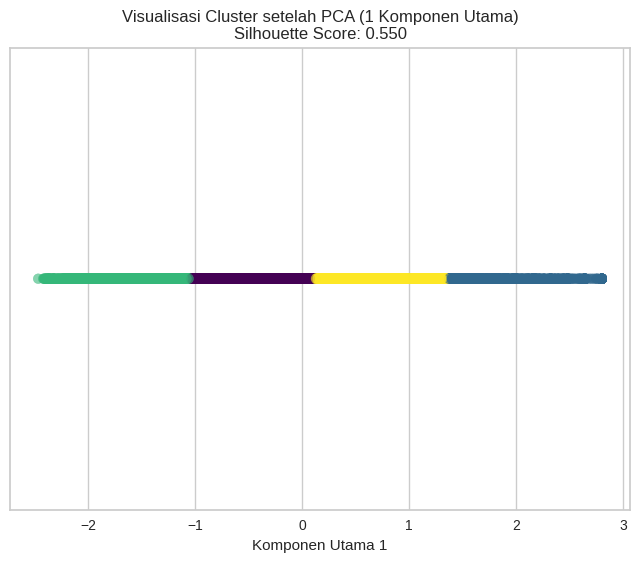

In [86]:
# 1. Evaluasi Model Sebelum Feature Selection
kmeans_before_fs = KMeans(n_clusters=optimal_k_elbow, random_state=42)
kmeans_before_fs.fit(X_scaled)
labels_before_fs = kmeans_before_fs.predict(X_scaled)
labels_before_fs = kmeans_before_fs.labels_
silhouette_before_fs = silhouette_score(X_scaled, labels_before_fs)
print(f"Silhouette Score sebelum feature selection: {silhouette_before_fs:.3f}")

# 2. Feature Selection dengan PCA
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X_scaled)
print(f"Varians yang dijelaskan oleh PCA: {sum(pca.explained_variance_ratio_):.2f}")

# 3. Evaluasi Model Setelah Feature Selection
kmeans_after_fs = KMeans(n_clusters=optimal_k_elbow, random_state=42, n_init=10)
kmeans_after_fs.fit(X_pca)
labels_after_fs = kmeans_after_fs.labels_
silhouette_after_fs = silhouette_score(X_pca, labels_after_fs)
print(f"Silhouette Score setelah feature selection: {silhouette_after_fs:.3f}")

# 4. Perbandingan Performa Model
print("\nPerbandingan Performa Model:")
print(f"- Silhouette Score sebelum feature selection: {silhouette_before_fs:.3f}")
print(f"- Silhouette Score setelah feature selection: {silhouette_after_fs:.3f}")

improvement = silhouette_after_fs - silhouette_before_fs
if improvement > 0.01:  # Threshold kecil untuk menghindari noise
    print("Feature selection meningkatkan performa model.")
else:
    print("Feature selection tidak terlalu berdampak.")

# 5. Visualisasi Cluster Setelah PCA
if X_pca.shape[1] == 2:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_after_fs, cmap='viridis', s=50, alpha=0.6)
    plt.title(f'Visualisasi Cluster setelah PCA (2 Komponen Utama)\nSilhouette Score: {silhouette_after_fs:.3f}')
    plt.xlabel('Komponen Utama 1')
    plt.ylabel('Komponen Utama 2')
    plt.colorbar(scatter, label='Cluster')
    plt.show()
elif X_pca.shape[1] == 1:
    plt.figure(figsize=(8, 6))
    plt.scatter(X_pca[:, 0], [0] * len(X_pca), c=labels_after_fs, cmap='viridis', s=50, alpha=0.6)
    plt.title(f'Visualisasi Cluster setelah PCA (1 Komponen Utama)\nSilhouette Score: {silhouette_after_fs:.3f}')
    plt.xlabel('Komponen Utama 1')
    plt.yticks([])
    plt.show()
else:
    print("Visualisasi hanya mendukung 1 atau 2 komponen utama.")

## **d. Visualisasi Hasil Clustering**

Setelah model clustering dilatih dan jumlah cluster optimal ditentukan, langkah selanjutnya adalah menampilkan hasil clustering melalui visualisasi.

Berikut adalah **rekomendasi** tahapannya.
1. Tampilkan hasil clustering dalam bentuk visualisasi, seperti grafik scatter plot atau 2D PCA projection.

Varians yang dijelaskan oleh PCA: 100.00%


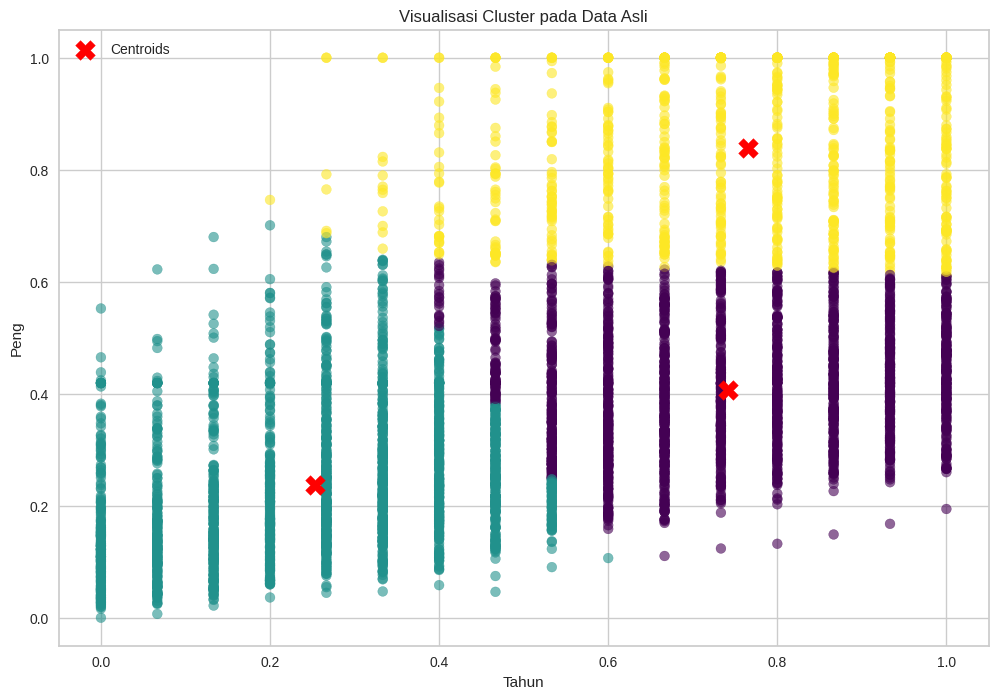

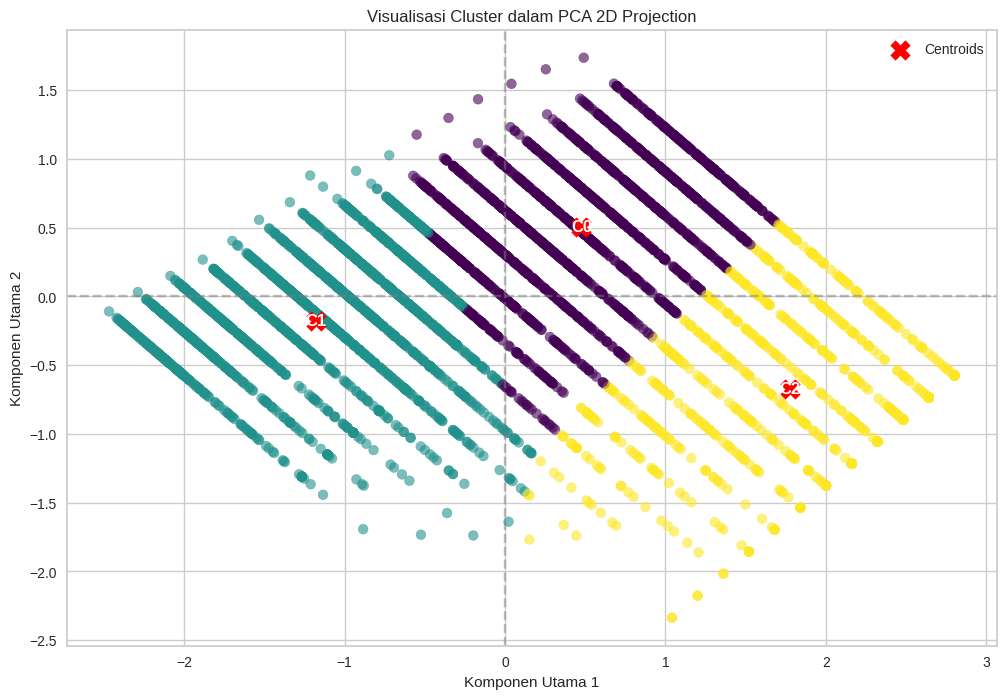

In [87]:
# 1. Clustering dengan K-Means menggunakan jumlah cluster optimal
# Gunakan hasil clustering terbaik
df['cluster'] = kmeans.labels_

# 2. Reduksi Dimensi dengan PCA untuk Visualisasi 2D
pca = PCA(n_components=2)  # Reduksi ke 2 komponen utama
X_pca = pca.fit_transform(X_scaled)
print(f"Varians yang dijelaskan oleh PCA: {sum(pca.explained_variance_ratio_):.2%}")

# Menambahkan hasil PCA ke dataframe
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

# 3. Visualisasi Cluster dengan Scatter Plot pada Data Asli
plt.figure(figsize=(12, 8))
plt.scatter(
    df['tahun'], df['peng'],
    c=df['cluster'], cmap='viridis', s=50, alpha=0.6
)

# Menambahkan centroid pada data asli
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    c='red', s=200, marker='X', label='Centroids'
)

plt.title('Visualisasi Cluster pada Data Asli')
plt.xlabel('Tahun')
plt.ylabel('Peng')
plt.legend()
plt.show()

# 4. Visualisasi Cluster dalam Ruang PCA (2D Projection)
plt.figure(figsize=(12, 8))
plt.scatter(
    df['pca_1'], df['pca_2'],
    c=df['cluster'], cmap='viridis', s=50, alpha=0.6
)

# Menambahkan centroid ke dalam visualisasi PCA
pca_centroids = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    pca_centroids[:, 0], pca_centroids[:, 1],
    c='red', s=200, marker='X', label='Centroids'
)

plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

for i, (x, y) in enumerate(zip(pca_centroids[:, 0], pca_centroids[:, 1])):
    plt.text(x, y, f'C{i}', fontsize=12, fontweight='bold', ha='center', va='center', color='white')

plt.title('Visualisasi Cluster dalam PCA 2D Projection')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend()
plt.show()


## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

**Tutorial: Melakukan Inverse Transform pada Data Target Setelah Clustering**

Setelah melakukan clustering dengan model **KMeans**, kita perlu mengembalikan data yang telah diubah (normalisasi, standarisasi, atau label encoding) ke bentuk aslinya. Berikut adalah langkah-langkahnya.

---

**1. Tambahkan Hasil Label Cluster ke DataFrame**
Setelah mendapatkan hasil clustering, kita tambahkan label cluster ke dalam DataFrame yang telah dinormalisasi.

```python
df_normalized['Cluster'] = model_kmeans.labels_
```

Lakukan Inverse Transform pada feature yang sudah dilakukan Labelisasi dan Standararisasi. Berikut code untuk melakukannya:
label_encoder.inverse_transform(X_Selected[['Fitur']])

Lalu masukkan ke dalam kolom dataset asli atau membuat dataframe baru
```python
df_normalized['Fitur'] = label_encoder.inverse_transform(df_normalized[['Fitur']])
```
Masukkan Data yang Sudah Di-Inverse ke dalam Dataset Asli atau Buat DataFrame Baru
```python
df_original['Fitur'] = df_normalized['Fitur']
```


Data asli setelah inverse transform dengan label cluster:
      tahun      peng peng_binned  provinsi_BALI  provinsi_BANTEN  \
0  0.536364  0.437195      rendah          False            False   
1  0.555989  0.441695      rendah          False            False   
2  0.575614  0.447155      rendah          False            False   
3  0.595239  0.452553      rendah          False            False   
4  0.614864  0.458700      rendah          False            False   

   provinsi_BENGKULU  provinsi_DI YOGYAKARTA  provinsi_DKI JAKARTA  \
0              False                   False                 False   
1              False                   False                 False   
2              False                   False                 False   
3              False                   False                 False   
4              False                   False                 False   

   provinsi_GORONTALO  provinsi_INDONESIA  ...  provinsi_SUMATERA BARAT  \
0               False         

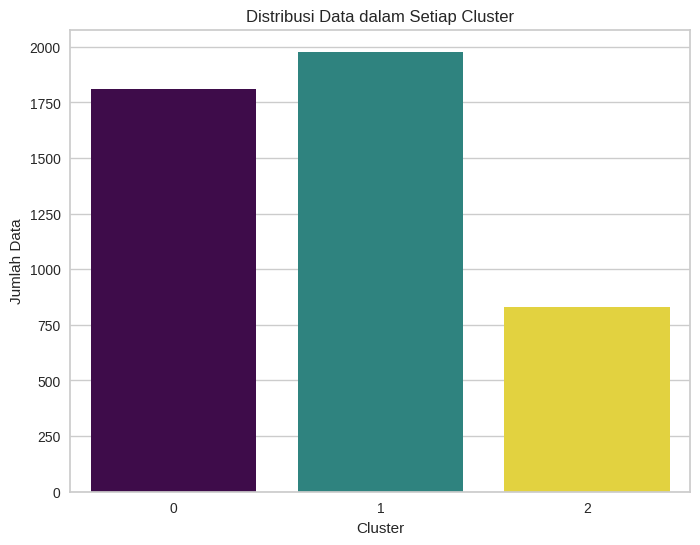

In [88]:
# 1. Tambahkan hasil label cluster ke DataFrame hasil normalisasi
df_normalized = df.copy()
df_normalized['cluster'] = kmeans.labels_

# 2. Buat salinan DataFrame asli untuk menyimpan hasil inverse transform
df_original = df.copy()

# 3. Lakukan Inverse Transform pada fitur yang distandarisasi
df_original[['tahun', 'peng']] = scaler.inverse_transform(df_normalized[['tahun', 'peng']])

# 4. Pastikan 'Fitur' ada di DataFrame sebelum membuat LabelEncoder
if 'Fitur' in df.columns:
    label_encoder = LabelEncoder()

    if not np.issubdtype(df['Fitur'].dtype, np.number):
        df['Fitur'] = label_encoder.fit_transform(df['Fitur'])  # Encode
    df_original['Fitur'] = label_encoder.inverse_transform(df['Fitur'])

# 5. Tambahkan label cluster ke dataset asli
df_original['cluster'] = df_normalized['cluster']

# 6. Menampilkan hasil setelah inverse transform
print("\nData asli setelah inverse transform dengan label cluster:")
print(df_original.head())

# 7. Menampilkan distribusi cluster
print("\nDistribusi Data pada Setiap Cluster:")
print(df_original['cluster'].value_counts())

# 8. Visualisasi Distribusi Cluster dengan Bar Plot
plt.figure(figsize=(8, 6))
sns.countplot(x=df_original['cluster'], hue=df_original['cluster'], palette='viridis', legend=False)
plt.title('Distribusi Data dalam Setiap Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah Data')
plt.show()


### Inverse Data Jika Melakukan Normalisasi/Standardisasi

Inverse Transform untuk Data yang Distandarisasi
Jika data numerik telah dinormalisasi menggunakan StandardScaler atau MinMaxScaler, kita bisa mengembalikannya ke skala asli:
```python
df_normalized[['Fitur_Numerik']] = scaler.inverse_transform(df_normalized[['Fitur_Numerik']])
```

Statistik Deskriptif per Cluster:
        tahun                                 peng                           \
        count         mean  median       std count          mean     median   
cluster                                                                       
0        1811  2018.112645  2018.0  2.425580  1811  5.842332e+05   581213.0   
1        1978  2010.792720  2011.0  2.296994  1978  3.652744e+05   335257.5   
2         831  2018.483755  2019.0  2.769353   831  1.143686e+06  1139676.0   

                        
                   std  
cluster                 
0        141104.360589  
1        166371.469835  
2        170292.582436  


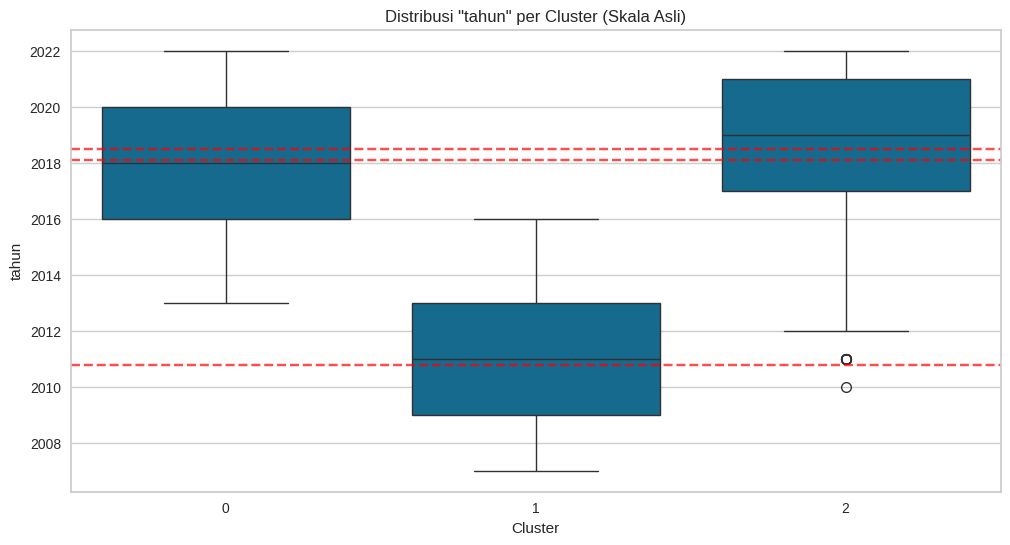

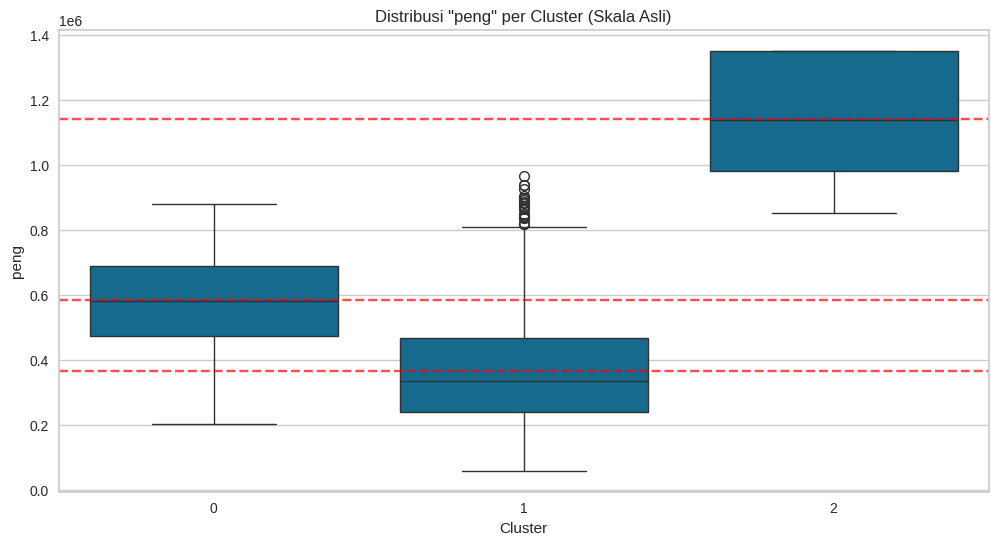

In [89]:
# 1. Buat salinan data normalisasi
df_scaled = df.copy()  # Buat salinan data yang telah dinormalisasi

# 2. Inverse Transform (Kembalikan ke Skala Asli)
df_original[numerical_columns] = min_max_scaler.inverse_transform(df_scaled[numerical_columns])
df_original['cluster'] = df_scaled['cluster']  # Simpan hasil cluster ke df_original

# 3. Analisis Statistik Deskriptif Per Cluster
cluster_stats = df_original.groupby('cluster')[numerical_columns].agg(['mean', 'median', 'std'])

# Analisis Statistik Deskriptif Per Cluster (Menambahkan jumlah data di setiap cluster)
cluster_stats = df_original.groupby('cluster')[numerical_columns].agg(['count', 'mean', 'median', 'std'])

# Menampilkan hasil statistik deskriptif
print("Statistik Deskriptif per Cluster:")
print(cluster_stats)

# 4. Visualisasi Distribusi Setiap Fitur Per Cluster
for col in numerical_columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='cluster', y=col, data=df_original)
    means = df_original.groupby('cluster')[col].mean()
    for i, mean in enumerate(means):
        plt.axhline(mean, linestyle='dashed', color='red', alpha=0.7)
    plt.title(f'Distribusi "{col}" per Cluster (Skala Asli)')
    plt.xlabel('Cluster')
    plt.ylabel(col)
    plt.show()

Setelah melakukan clustering, langkah selanjutnya adalah menganalisis karakteristik dari masing-masing cluster berdasarkan fitur yang tersedia.

Berikut adalah **rekomendasi** tahapannya.
1. Analisis karakteristik tiap cluster berdasarkan fitur yang tersedia (misalnya, distribusi nilai dalam cluster).
2. Berikan interpretasi: Apakah hasil clustering sesuai dengan ekspektasi dan logika bisnis? Apakah ada pola tertentu yang bisa dimanfaatkan?

#Analisis Karakteristik Cluster dari Model KMeans

Berikut adalah analisis karakteristik untuk setiap cluster yang dihasilkan dari model KMeans.

#Cluster 1:
- **Rata-rata Tahun:** 2018.11
- **Rata-rata Pengeluaran:** 584.233
- **Analisis:**Cluster ini terdiri dari data yang relatif baru (sekitar tahun 2018) dengan pengeluaran menengah. Unit dalam cluster ini cenderung stabil secara pengeluaran dan berasal dari tahun yang lebih baru, kemungkinan mencerminkan kelompok yang mapan atau institusi yang baru berkembang dengan aktivitas pengeluaran reguler.

#Cluster 2:
- **Rata-rata Tahun:** 2010.79
- **Rata-rata Pengeluaran:** 365.274
- **Analisis:** Cluster ini mencerminkan kelompok dengan pengeluaran terendah dan berasal dari tahun-tahun yang lebih lama (2010-an). Kemungkinan ini merepresentasikan entitas yang lebih tua atau lama berdiri namun sudah tidak aktif lagi, atau pengeluarannya kecil karena efisiensi atau keterbatasan dana.

#Cluster 3:
- **Rata-rata Tahun:** 2018.48
- **Rata-rata Pengeluaran:** 1.143.686
- **Analisis:** Ini adalah cluster dengan pengeluaran tertinggi, dan berasal dari tahun-tahun yang relatif baru. Kelompok ini menunjukkan entitas yang sangat aktif secara finansial, kemungkinan besar termasuk organisasi besar, proyek pemerintah, atau institusi dengan dana besar dan aktivitas pengeluaran tinggi.


# Contoh interpretasi [TEMPLATE]
# Analisis Karakteristik Cluster dari Model KMeans

Berikut adalah analisis karakteristik untuk setiap cluster yang dihasilkan dari model KMeans.

## Cluster 1:
- **Rata-rata Annual Income (k$):** 48,260  
- **Rata-rata Spending Score (1-100):** 56.48  
- **Analisis:** Cluster ini mencakup pelanggan dengan pendapatan tahunan menengah dan tingkat pengeluaran yang cukup tinggi. Pelanggan dalam cluster ini cenderung memiliki daya beli yang moderat dan mereka lebih cenderung untuk membelanjakan sebagian besar pendapatan mereka.

## Cluster 2:
- **Rata-rata Annual Income (k$):** 86,540  
- **Rata-rata Spending Score (1-100):** 82.13  
- **Analisis:** Cluster ini menunjukkan pelanggan dengan pendapatan tahunan tinggi dan pengeluaran yang sangat tinggi. Pelanggan di cluster ini merupakan kelompok premium dengan daya beli yang kuat dan cenderung mengeluarkan uang dalam jumlah besar untuk produk atau layanan.

## Cluster 3:
- **Rata-rata Annual Income (k$):** 87,000  
- **Rata-rata Spending Score (1-100):** 18.63  
- **Analisis:** Cluster ini terdiri dari pelanggan dengan pendapatan tahunan yang tinggi tetapi pengeluaran yang rendah. Mereka mungkin memiliki kapasitas finansial yang baik namun tidak terlalu aktif dalam berbelanja. Ini bisa menunjukkan bahwa mereka lebih selektif dalam pengeluaran mereka atau mungkin lebih cenderung untuk menyimpan uang.

# **7. Mengeksport Data**

Simpan hasilnya ke dalam file CSV.

In [90]:
# Simpan DataFrame df_original ke file CSV tanpa menyertakan index
df_original.to_csv('Dataset_inisiasi.csv', index=False)
print("Data telah diekspor ke 'Dataset_inisiasi.csv'")

Data telah diekspor ke 'Dataset_inisiasi.csv'
